In [1]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║                                                                      ║
# ║     Master Miage I&I - M2    -     University of Lorraine / IDMC     ║
# ║                                                                      ║
# ╟──────────────────────────────────────────────────────────────────────╢
# ║                                                                      ║
# ║                   Practical Work - Big Data                          ║
# ║                                                                      ║
# ║                   Author: Boulcourt Raphaël                          ║
# ║                                                                      ║
# ╟──────────────────────────────────────────────────────────────────────╢
# ║                                                                      ║
# ║ Configuration:                                                       ║
# ║                                                                      ║
# ║   ► Dataset path: Place the CSV in a folder named 'dataset/'        ║
# ║     next to this notebook.                                           ║
# ║                                                                      ║
# ║   ► Libraries: Some packages may need to be installed.              ║
# ║     Check requirements.txt.                                          ║
# ║                                                                      ║
# ║ 2019-02                                                              ║
# ╚══════════════════════════════════════════════════════════════════════╝





In [2]:
# ┌──────────────────────────────────────────────────────────────────────┐
# │ 0 - Initialization                                                   │ 
# └──────────────────────────────────────────────────────────────────────┘






In [3]:
# Import modules
# ──────────────────

# ▪ Global

import warnings
import numpy as np                  # Numpy - Mathematical calculations
import re                           # Regex - Used for string conversions
import pandas as pd                 # Pandas - Used for data manipulation
import matplotlib.pyplot as plt     # Matplotlib - Used for generating plots
import seaborn as sns               # Seaborn - Matplotlib extension for advanced plots

# ▪ scikit-learn (https://scikit-learn.org/)

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *

# Settings
# ───────────

# ▪ Global - Dataset currency (assumed to be euros (€))

set_currency = "€"

# ▪ Global - Suppress Python warnings

warnings.filterwarnings("ignore")

# ▪ matplotlib - Annotation box style

annotate_bbox_settings = dict(boxstyle = "round,pad=0.3", fc= "cyan", ec= "#404040", lw = 1)
annotate_fontsize_settings = 11
annotate_rotate_label_degree = -45

# ▪ Seaborn - Default color palette

sns_default_palette = "PuBu"
sns.set_context("notebook")

sns.set_style("whitegrid")






In [4]:
# ┌──────────────────────────────────────────────────────────────────────┐
# │ 1 - Data loading / schema definition                      │ 
# └──────────────────────────────────────────────────────────────────────┘






In [5]:
# Data loading
# ──────────────────────

data = pd.read_csv("dataset/churn_dataset.csv")








In [6]:
# Display of the first 10 records of the dataset
# ──────────────────────────────────────────────────────────

data.head(11)






,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [7]:
# Dataset schema visualization
# ─────────────────────────────────────────

data.info()

# ▪ Summary

print("\nDataset information:")
print("────────────────────────────────────\n")
print("Contains:\n")
print("   ► \033[1m{}\033[0m columns".format(data.shape[1]))
print("   ► \033[1m{}\033[0m records\n".format(data.shape[0]-1))
print("Consists of:\n")
print("   ► \033[1m{}\033[0m object column(s)".format(len(data.select_dtypes(include=['object']).columns)))
print("   ► \033[1m{}\033[0m numerical column(s)".format(len(data.select_dtypes(include=['int64', 'float64']).columns)))






<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
customerID          7043 non-null object
gender              7043 non-null object
SeniorCitizen       7043 non-null int64
Partner             7043 non-null object
Dependents          7043 non-null object
tenure              7043 non-null int64
PhoneService        7043 non-null object
MultipleLines       7043 non-null object
InternetService     7043 non-null object
OnlineSecurity      7043 non-null object
OnlineBackup        7043 non-null object
DeviceProtection    7043 non-null object
TechSupport         7043 non-null object
StreamingTV         7043 non-null object
StreamingMovies     7043 non-null object
Contract            7043 non-null object
PaperlessBilling    7043 non-null object
PaymentMethod       7043 non-null object
MonthlyCharges      7043 non-null float64
TotalCharges        7043 non-null object
Churn               7043 non-null object
dtypes: float64(1), int64(2), obj

In [8]:
# ┌──────────────────────────────────────────────────────────────────────┐
# │ 2 - Exploration / Visualization / Data Cleaning     │ 
# └──────────────────────────────────────────────────────────────────────┘






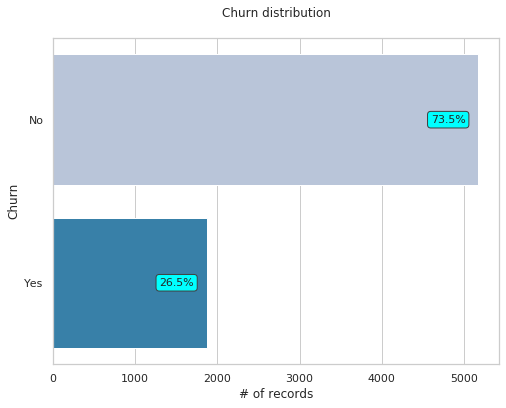

In [9]:
# Exploration / Visualization - Churn distribution
# ───────────────────────────────────────────────────────

plt.figure(figsize = (8,6))

graph_churn_total = sns.countplot(y = "Churn", data = data, palette = sns_default_palette)

total = len(data["Churn"])

for p in graph_churn_total.patches:
    percentage = "{:.1f}%".format(100 * p.get_width()/total)
    x = p.get_x() + p.get_width() + 0.02
    y = p.get_y() + p.get_height()/2
    graph_churn_total.annotate(percentage, (x, y),
                               ha = "center",
                               va = "center" ,
                               xytext = (-30, 0), 
                               textcoords = "offset points",
                               bbox = annotate_bbox_settings,
                               fontsize = annotate_fontsize_settings
                              )

plt.xlabel("# of records")
plt.ylabel("Churn")
plt.title("Churn distribution\n")
plt.show()






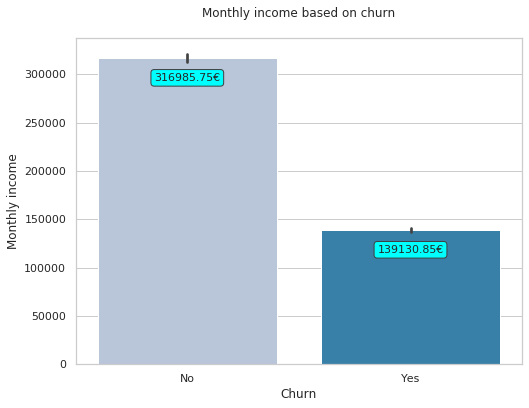

In [10]:
# Exploration / Visualization - Monthly charges and churn
# ─────────────────────────────────────────────────────────

plt.figure(figsize = (8,6))

graph_monthly_charges = sns.barplot(x = data["Churn"], y = data["MonthlyCharges"], 
                                   estimator = sum, palette = sns_default_palette
                                  )

for p in graph_monthly_charges.patches:
    graph_monthly_charges.annotate("%.2f" % p.get_height() + set_currency, 
                                  (p.get_x() + p.get_width() / 2, p.get_height()), 
                                   ha = "center",
                                   va = "center" ,
                                   xytext = (0, -20),
                                   textcoords = "offset points",
                                   bbox = annotate_bbox_settings,
                                   fontsize = annotate_fontsize_settings
                                  )
plt.xlabel("Churn")
plt.ylabel("Monthly income")
plt.title("Monthly income based on churn\n")
plt.show()






In [11]:
# Data cleaning
# ─────────────────────

# ▪ Removal of the 'customerID' column, not useful for analysis

data.drop(["customerID"],axis = 1,inplace = True)

# ▪ Converting TotalCharges to float

data.TotalCharges = pd.to_numeric(data.TotalCharges, errors = "coerce")

# ▪ Converting Yes/No columns to 0/1

columns_to_convert = ["Partner", 
                      "Dependents", 
                      "PhoneService", 
                      "MultipleLines",
                      "OnlineSecurity",
                      "OnlineBackup",
                      "DeviceProtection",
                      "TechSupport",
                      "StreamingTV",
                      "StreamingMovies",
                      "PaperlessBilling", 
                      "Churn"]

for item in columns_to_convert:
    data[item] = [1 if each == "Yes" else 0 if each == "No" else -1 for each in data[item]]

data.gender = [1 if each == "Male" else 0 for each in data.gender]






In [12]:
# Data cleaning - Validation
# ──────────────────────────────────
    
data.info()

# ▪ Summary

print("\nDataset information:")
print("────────────────────────────────────\n")
print("Contains:\n")
print("   ► \033[1m{}\033[0m columns".format(data.shape[1]))
print("   ► \033[1m{}\033[0m records\n".format(data.shape[0]-1))
print("Consists of:\n")
print("   ► \033[1m{}\033[0m object column(s)".format(len(data.select_dtypes(include=['object']).columns)))
print("   ► \033[1m{}\033[0m numerical column(s)".format(len(data.select_dtypes(include=['int64', 'float64']).columns)))






<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
gender              7043 non-null int64
SeniorCitizen       7043 non-null int64
Partner             7043 non-null int64
Dependents          7043 non-null int64
tenure              7043 non-null int64
PhoneService        7043 non-null int64
MultipleLines       7043 non-null int64
InternetService     7043 non-null object
OnlineSecurity      7043 non-null int64
OnlineBackup        7043 non-null int64
DeviceProtection    7043 non-null int64
TechSupport         7043 non-null int64
StreamingTV         7043 non-null int64
StreamingMovies     7043 non-null int64
Contract            7043 non-null object
PaperlessBilling    7043 non-null int64
PaymentMethod       7043 non-null object
MonthlyCharges      7043 non-null float64
TotalCharges        7032 non-null float64
Churn               7043 non-null int64
dtypes: float64(2), int64(15), object(3)
memory usage: 1.1+ MB

Informations sur le je

In [13]:
# Display of the first 10 records of the cleaned dataset
# ──────────────────────────────────────────────────────────────────

data.head(11)






,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,-1,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0
2,1,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1
3,1,0,0,0,45,0,-1,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1
5,0,0,0,0,8,1,1,Fiber optic,0,0,1,0,1,1,Month-to-month,1,Electronic check,99.65,820.50,1
6,1,0,0,1,22,1,1,Fiber optic,0,1,0,0,1,0,Month-to-month,1,Credit card (automatic),89.10,1949.40,0
7,0,0,0,0,10,0,-1,DSL,1,0,0,0,0,0,Month-to-month,0,Mailed check,29.75,301.90,0
8,0,0,1,0,28,1,1,Fiber optic,0,0,1,1,1,1,Month-to-month,1,Electronic check,104.80,3046.05,1
9,1,0,0,1,62,1,0,DSL,1,1,0,0,0,0,One year,0,Bank transfer (automatic),56.15,3487.95,0


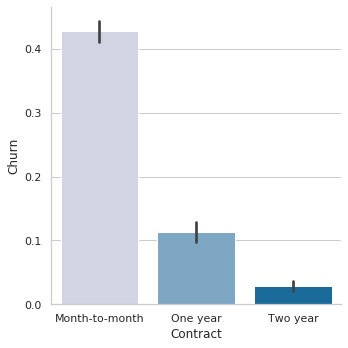

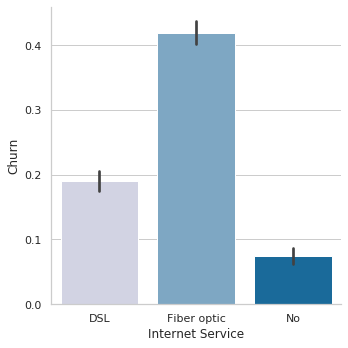

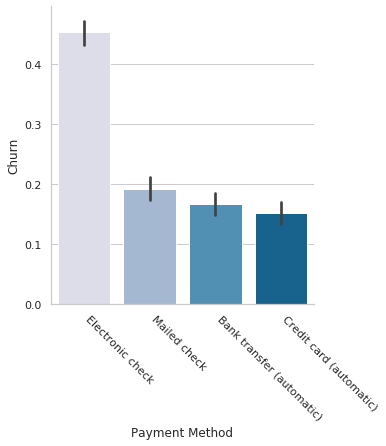

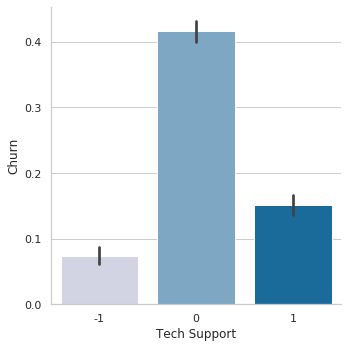

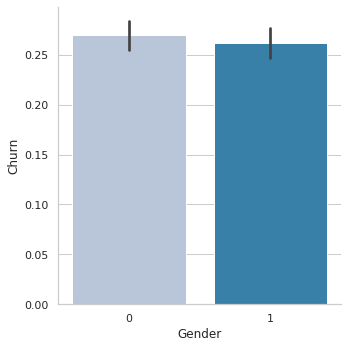

In [14]:
# Exploration / Visualization - Churn and categorical variables
# ────────────────────────────────────────────────────────────────

def graph_prob(data_select) :
    graph = sns.catplot(x = data_select,
                        y = "Churn",
                        data = data,
                        kind = "bar",
                        height = 5,
                        aspect = 1, 
                        palette = sns_default_palette
                       )
    
    count_rows_entry_occurences = data[data_select].nunique()
    
    if (count_rows_entry_occurences > 3):
        graph.set_xticklabels(rotation = annotate_rotate_label_degree,
                              horizontalalignment = "left"
                             )

    label_string_cleaning = (re.sub("([A-Z])", " \\1", data_select).strip()).title()

    plt.xlabel(label_string_cleaning)
    plt.show()

# ▪ Attrition en fonction du type contrat

graph_prob("Contract")

# ▪ Attrition en fonction du type service internet

graph_prob("InternetService")

# ▪ Attrition en fonction de la méthode de paiement

graph_prob("PaymentMethod")

# ▪ Attrition en fonction de l'accès au support

graph_prob("TechSupport")

# ▪ Attrition en fonction du genre

graph_prob("gender")






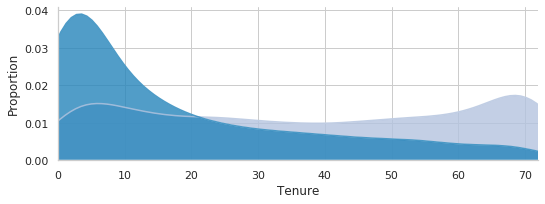

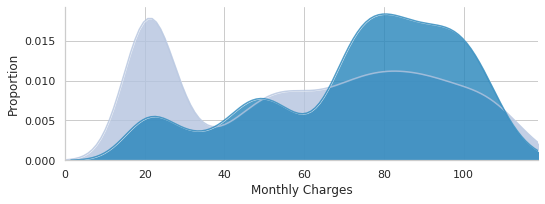

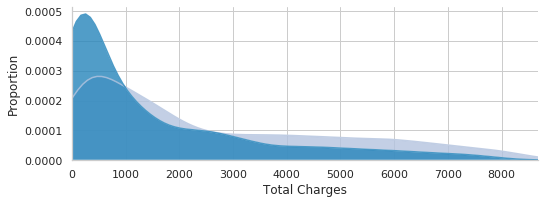

In [15]:
# Exploration / Visualization - Churn and numerical variables
# ─────────────────────────────────────────────────────────────

def graph_proportion(data_select) :
    graph = sns.FacetGrid(data, hue = "Churn",
                          aspect = 2.5,
                          palette = sns_default_palette
                         )

    graph.map(sns.kdeplot,
              data_select,
              shade = True,
              alpha = 0.8

             )
    graph.set(xlim = (0, data[data_select].max()))
    
    graph.set_axis_labels(data_select,
                          "Density"
                         )
    
    label_string_cleaning = (re.sub("([A-Z])", " \\1", data_select).strip()).title()

    plt.xlabel(label_string_cleaning)
    plt.show()
   
# ▪ Proportions d'attrition en fonction de la durée d'engagement

graph_proportion("tenure")

# ▪ Proportions d'attrition en fonction des charges mensuelles

graph_proportion("MonthlyCharges")

# ▪ Proportions d'attrition en fonction des charges totales

graph_proportion("TotalCharges")






In [16]:
# ┌──────────────────────────────────────────────────────────────────────┐
# │ 3 - Réalisation des transformations nécessaires                      │ 
# └──────────────────────────────────────────────────────────────────────┘






In [17]:
# Transformations - Categorical variables to dummy variables
# ─────────────────────────────────────────────────────────────────────

# ▪ Creating dummy variables

data_normalized = pd.get_dummies(data = data)

# ▪ Checking for null values

print("\nDataset information:")
print("────────────────────────────────────\n")
print("Presence of null values:\n")
print("   ► \033[1m{}\033[0m null values".format(data_normalized.isnull().values.sum()))







Informations sur le jeu de données :
────────────────────────────────────

Présence de valeurs nulles :

   ► Dans 11 enregistrements


In [18]:
# ▪ On éjecte les valeurs nulles des records (quick method)

data_normalized.dropna(inplace = True)






In [19]:
# Display of the first 10 records of the transformed dataset
# ──────────────────────────────────────────────────────────────────────

data_normalized.head(11)






,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,-1,0,1,0,...,1,0,0,1,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,...,1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,...,1,0,0,1,0,0,0,0,0,1
3,1,0,0,0,45,0,-1,1,0,1,...,1,0,0,0,1,0,1,0,0,0
4,0,0,0,0,2,1,0,0,0,0,...,0,1,0,1,0,0,0,0,1,0
5,0,0,0,0,8,1,1,0,0,1,...,0,1,0,1,0,0,0,0,1,0
6,1,0,0,1,22,1,1,0,1,0,...,0,1,0,1,0,0,0,1,0,0
7,0,0,0,0,10,0,-1,1,0,0,...,1,0,0,1,0,0,0,0,0,1
8,0,0,1,0,28,1,1,0,0,1,...,0,1,0,1,0,0,0,0,1,0
9,1,0,0,1,62,1,0,1,1,0,...,1,0,0,0,1,0,1,0,0,0


In [20]:
# ┌──────────────────────────────────────────────────────────────────────┐
# │ 4 - Sélection des informations                                       │ 
# └──────────────────────────────────────────────────────────────────────┘






In [21]:
# Correlation of churn with the different variables
# ─────────────────────────────────────────────────────────

# ▪ Variance table generated from the transformed dataset

pd.DataFrame(data_normalized.corr()["Churn"].sort_values())






,Churn
tenure,-0.354049
Contract_Two year,-0.301552
InternetService_No,-0.227578
TotalCharges,-0.199484
Contract_One year,-0.178225
Dependents,-0.163128
Partner,-0.149982
PaymentMethod_Credit card (automatic),-0.134687
InternetService_DSL,-0.124141
PaymentMethod_Bank transfer (automatic),-0.118136


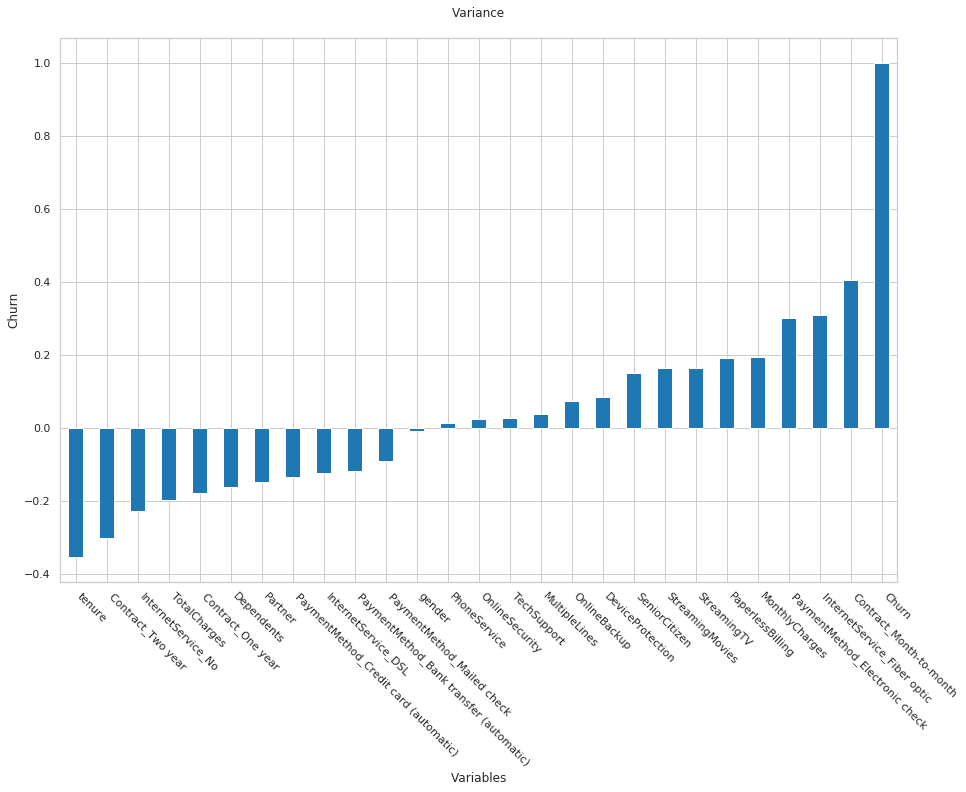

In [22]:
# Correlation of churn with variables
# ─────────────────────────────────────────────────────────

# ▪ Bar chart of correlations

plt.figure(figsize = (15,10))

data_select = data_normalized.corr()["Churn"].sort_values(ascending = True)

graph_churn_var = data_select.plot(kind="bar")

graph_churn_var.set_xlabel("Variables")
graph_churn_var.set_ylabel("Churn")
plt.xticks(rotation = annotate_rotate_label_degree, horizontalalignment = "left")
plt.title("Variance\n")
plt.show()






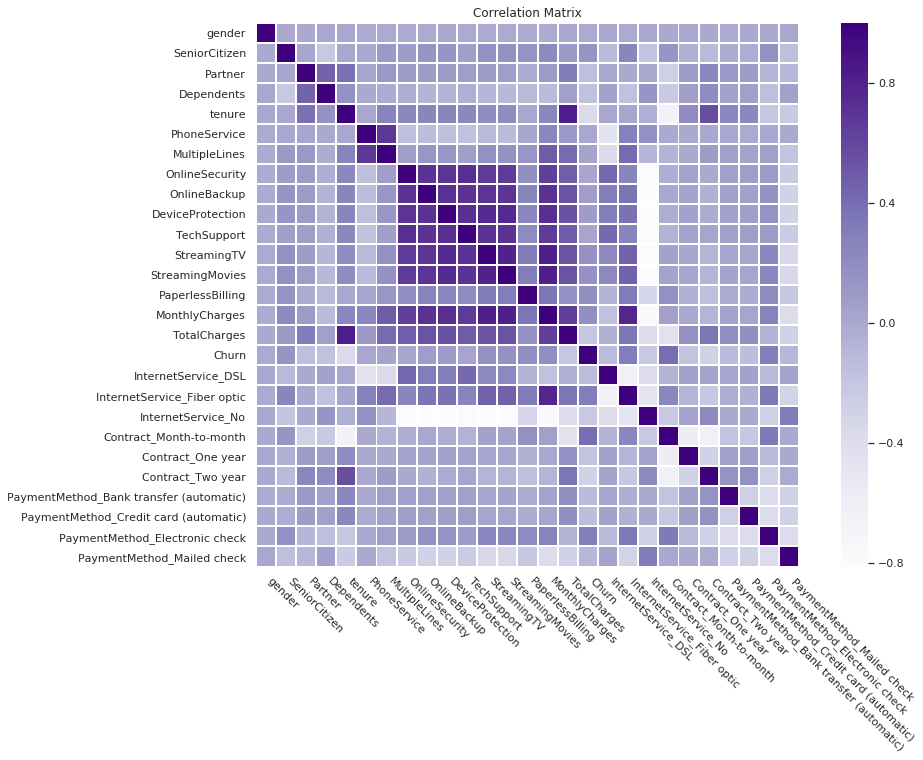

In [23]:
# ▪ Correlation matrix from the transformed dataset

plt.figure(figsize = (15,10))

correlation_matrix = data_normalized.corr()
sns.heatmap(data = correlation_matrix,
            square = True,
            cmap = "Purples",
            linewidth = 1
           )

plt.xticks(rotation = annotate_rotate_label_degree, 
           horizontalalignment = "left"
          )

plt.title("Correlation Matrix")
plt.show()






In [24]:
# ┌──────────────────────────────────────────────────────────────────────┐
# │ 5 - Model Training                                           │ 
# └──────────────────────────────────────────────────────────────────────┘






In [25]:
# Dataset preparation
# ─────────────────────────────

# ▪ Assign churn values as target

y = data_normalized.Churn.values

# ▪ Removal of the header in the "Churn" column

new_data = data_normalized.drop(["Churn"],axis=1)

# ▪ Normalization of values so that they are between 0 and 1

X = (new_data-np.min(new_data))/(np.max(new_data)-np.min(new_data)).values






In [26]:
# ▪ Seed for reproducibility
random_state = 1984  # The best year! (⌐■_■)

# ▪ Dataset split:
#   - 80% training
#   - 20% testinging
#   (stratify to preserve the churn rate)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=random_state, stratify=y
)







In [27]:
# Model Training
# ─────────────────────────

# ▪ Models with class imbalance handling
LR = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=random_state)
RF = RandomForestClassifier(
    n_estimators=100,          # reasonable default value
    class_weight='balanced',
    random_state=random_state,
    n_jobs=-1
)

# ▪ Fitting the models
LR.fit(X_train, y_train)
RF.fit(X_train, y_train)

# ▪ Predicted probabilities for ROC curves
y_LR = LR.predict_proba(X_test)[:, 1]
y_RF = RF.predict_proba(X_test)[:, 1]

# ▪ ROC curves
false_positive_rate_LR, true_positive_rate_LR, threshold_LR = roc_curve(y_test, y_LR)
false_positive_rate_RF, true_positive_rate_RF, threshold_RF = roc_curve(y_test, y_RF)







In [28]:
# ┌──────────────────────────────────────────────────────────────────────┐
# │ 6 - Model Evaluation                                              │ 
# └──────────────────────────────────────────────────────────────────────┘






In [29]:
# Evaluation preparation
# ───────────────────────────

def print_training_scores(y_true, y_pred):
    
    acc_score = accuracy_score(y_true, y_pred)
    pre_score = precision_score(y_true, y_pred)
    rec_score = recall_score(y_true, y_pred)                            
    f_score = f1_score(y_true, y_pred, average='weighted')
       
    print("\nDetails:")
    print("─────────\n")
    print("Accuracy              ► \033[1m{}\033[0m".format(acc_score))
    print("Precision             ► \033[1m{}\033[0m".format(pre_score))
    print("Recall                ► \033[1m{}\033[0m".format(rec_score))
    print("  Score F1 (f1 score) ► \033[1m{}\033[0m".format(f_score))






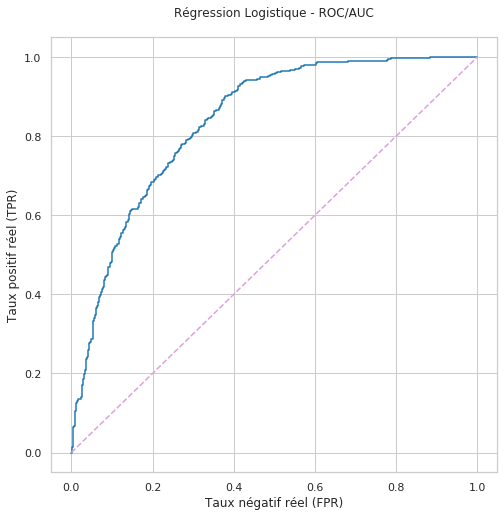


Détails :
─────────

Exactitude (accuracy) ► 0.7903340440653873
Précision (precision) ► 0.6242424242424243
      Rappel (recall) ► 0.5464190981432361
  Score F1 (f1 score) ► 0.7857034163468786


In [30]:
# Logistic Regression Evaluation
# ──────────────────────────────────────

# ▪ Plot

plt.figure(figsize = (8,8))

plt.step(false_positive_rate_LR, true_positive_rate_LR)
plt.plot([0, 1], ls= "dashed", color = "Plum")

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title("Logistic Regression - ROC/AUC\n")
plt.show()

# ▪ Value tables représentative

print_training_scores(y_test, LR.predict(X_test))






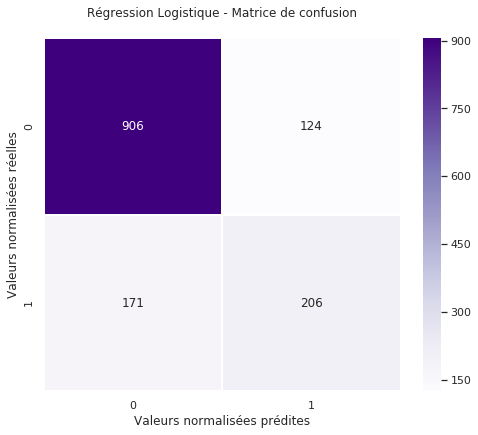

In [31]:
# ▪ Display of a confusion matrix

plt.figure(figsize = (8,6.5))

LR_confusion_matrix = confusion_matrix(y_test,LR.predict(X_test))
sns.heatmap(LR_confusion_matrix, annot = True, fmt = ".0f", cmap = "Purples", linewidth = 1)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix\n")
plt.show()






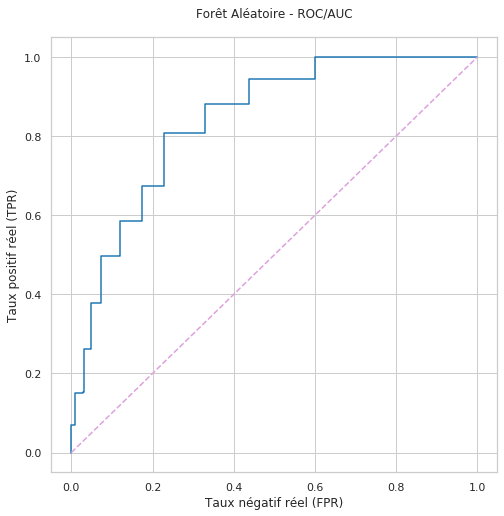


Détails :
─────────

Exactitude (accuracy) ► 0.7775408670931059
Précision (precision) ► 0.6025641025641025
      Rappel (recall) ► 0.4986737400530504
  Score F1 (f1 score) ► 0.7704498279176498


In [32]:
# Random Forest Evaluation
# ────────────────────────────────

# ▪ Plot

plt.figure(figsize = (8,8))

plt.step(false_positive_rate_RF, true_positive_rate_RF)
plt.plot([0, 1], ls= "dashed", color = "Plum")

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title("Random Forest - ROC/AUC\n")
plt.show()

# ▪ Value tables représentative

print_training_scores(y_test, RF.predict(X_test))






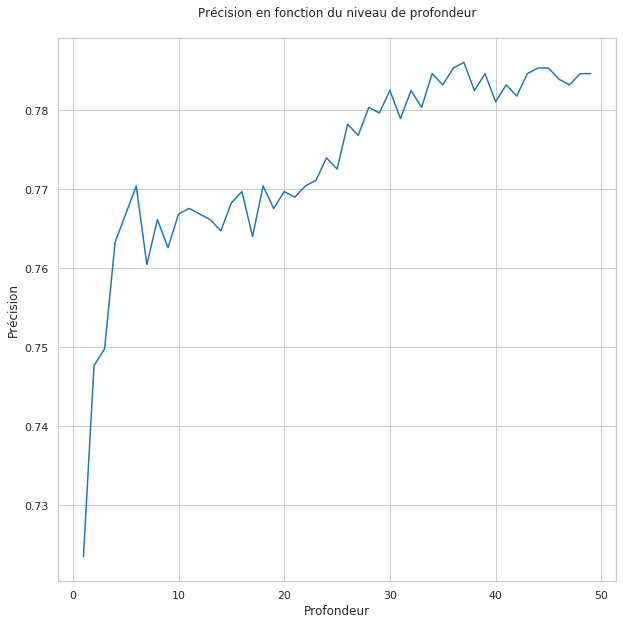

In [33]:
# ▪ Search for the best number of trees (n_estimators) from 1 to 50
#   (Note: this is NOT the depth. Depth = max_depth)

plt.figure(figsize=(10, 6))

score_array = []
for n_trees in range(1, 51):
    rf_loop = RandomForestClassifier(
        n_estimators=n_trees,
        class_weight='balanced',
        random_state=random_state,
        n_jobs=-1
    )
    rf_loop.fit(X_train, y_train)
    score_array.append(rf_loop.score(X_test, y_test))

plt.plot(range(1, 51), score_array, marker='o', markersize=3)
plt.xlabel("Number of trees (n_estimators)")
plt.ylabel("Accuracy")
plt.title("Accuracy vs number of trees\n")
plt.grid(True, alpha=0.3)
plt.show()







In [34]:
# ▪ Best number of trees (top 5)

rfc_range = pd.DataFrame(score_array, index=range(1, 51)).nlargest(5, 0)
rfc_range.columns = ["Accuracy"]
rfc_range.index.name = "n_estimators"
rfc_range







,Précision
Profondeur,
36,0.786070
35,0.785359
43,0.785359
44,0.785359
33,0.784648


In [ ]:
# ▪ Feature importances (final Random Forest)
#   Retraining with a good n_estimators (e.g. 100 or the best found)

best_n = 100  # ou rfc_range.index[0] si tu veux le top du loop
RF_final = RandomForestClassifier(
    n_estimators=best_n,
    class_weight='balanced',
    random_state=random_state,
    n_jobs=-1
)
RF_final.fit(X_train, y_train)

# Feature importances
importances = pd.Series(RF_final.feature_importances_, index=new_data.columns)
importances = importances.sort_values(ascending=False)

plt.figure(figsize=(10, 8))
importances.head(15).plot(kind='barh')
plt.title("Top 15 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\nTop 10 features:")
print(importances.head(10))







In [35]:
# Evaluation summary
# ─────────────────────────────

report_LR = classification_report(y_test, LR.predict(X_test))
report_RF = classification_report(y_test, RF.predict(X_test))

print("\nEvaluation summary:")
print("─────────────────────────────────\n")
print("Logistic Regression:\n")
print(report_LR)
print("Random Forest:\n")
print(report_RF)







Récapitulatif des évaluations :
─────────────────────────────────

Regression logistique :

              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1030
           1       0.62      0.55      0.58       377

    accuracy                           0.79      1407
   macro avg       0.73      0.71      0.72      1407
weighted avg       0.78      0.79      0.79      1407

Forêt Aléatoire :

              precision    recall  f1-score   support

           0       0.83      0.88      0.85      1030
           1       0.60      0.50      0.55       377

    accuracy                           0.78      1407
   macro avg       0.71      0.69      0.70      1407
weighted avg       0.77      0.78      0.77      1407

